In [1]:
# Loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load in the cleaned data
df = pd.read_csv('AviationData_Cleaned.csv')

# Quick check
print(df.shape)
df.head()

(18766, 32)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Total.Passengers,Fatal_Serious_Fraction,Is_Destroyed,Make_Model
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,0.0,0.0,588.0,VMC,Probable Cause,04-12-2014,588.0,0.0,0.0,BOEING 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,IMC,Probable Cause,02-05-2011,2.0,1.0,1.0,PIPER PA-28-140
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,0.0,0.0,4.0,VMC,Probable Cause,17-10-2016,5.0,0.2,0.0,DE HAVILLAND DHC-6
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,0.0,0.0,100.0,VMC,Probable Cause,11-06-2018,100.0,0.0,0.0,BOEING 727-200
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,1.0,VMC,Probable Cause,05-05-2011,1.0,0.0,0.0,BEECH C35


In [2]:
# Create a new column to categorize planes
# Planes with 20 or more passengers are 'Large', others are 'Small'
df['Plane_Size'] = df['Total.Passengers'].apply(lambda x: 'Large' if x >= 20 else 'Small')

# Check the split
print(df['Plane_Size'].value_counts())

Small    17912
Large      854
Name: Plane_Size, dtype: int64


In [3]:
# 1. Filter for Small Planes
small_planes = df[df['Plane_Size'] == 'Small']

# Group by Make, calculate the mean injury fraction, sort ascending, and get the top 15
small_makes_15 = small_planes.groupby('Make')['Fatal_Serious_Fraction'].mean().sort_values(ascending=True).head(15)

print("Top 15 Small Plane Makes with Lowest Injury Fractions:")
print(small_makes_15)

# 2. Filter for Large Planes
large_planes = df[df['Plane_Size'] == 'Large']

# Group by Make, calculate the mean injury fraction, sort ascending, and get the top 15
large_makes_15 = large_planes.groupby('Make')['Fatal_Serious_Fraction'].mean().sort_values(ascending=True).head(15)

print("\nTop 15 Large Plane Makes with Lowest Injury Fractions:")
print(large_makes_15)

Top 15 Small Plane Makes with Lowest Injury Fractions:
Make
AIRBUS                            0.029173
BOMBARDIER INC                    0.050000
MCDONNELL DOUGLAS                 0.051299
BOEING                            0.052832
BOMBARDIER                        0.053714
MAULE                             0.167145
AVIAT AIRCRAFT INC                0.173611
GRUMMAN ACFT ENG COR-SCHWEIZER    0.187500
AVIAT                             0.192308
AYRES                             0.203704
STINSON                           0.205923
ROCKWELL INTERNATIONAL            0.215000
DIAMOND AIRCRAFT IND INC          0.220588
BELLANCA                          0.226303
AERONCA                           0.234767
Name: Fatal_Serious_Fraction, dtype: float64

Top 15 Large Plane Makes with Lowest Injury Fractions:
Make
CESSNA                       0.000000
DEHAVILLAND                  0.000000
GRUMMAN                      0.000000
PIPER                        0.000000
MCDONNELL DOUGLAS            0.007846

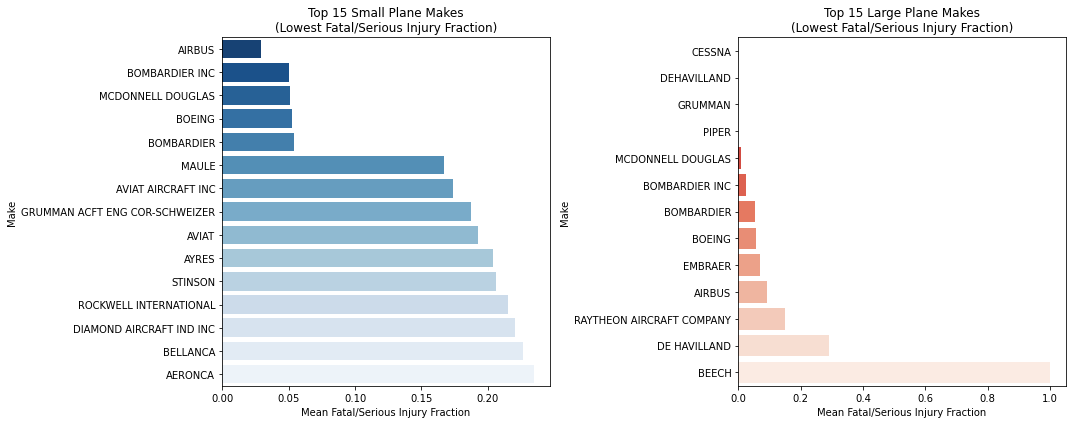

In [4]:
# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Small Planes
sns.barplot(x=small_makes_15.values, y=small_makes_15.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 15 Small Plane Makes\n(Lowest Fatal/Serious Injury Fraction)')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Make')

# Plot Large Planes
sns.barplot(x=large_makes_15.values, y=large_makes_15.index, ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 15 Large Plane Makes\n(Lowest Fatal/Serious Injury Fraction)')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Make')

plt.tight_layout()
plt.show()

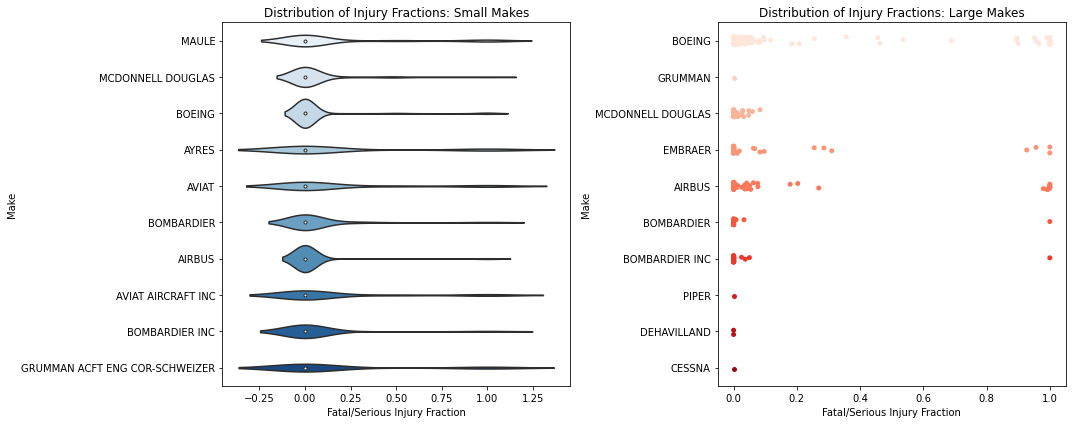

In [5]:
# Filter to only the top 10 makes for each size to make the plots readable
small_10 = small_planes[small_planes['Make'].isin(small_makes_15.head(10).index)]
large_10 = large_planes[large_planes['Make'].isin(large_makes_15.head(10).index)]

# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Violin plot for Small Planes
sns.violinplot(data=small_10, x='Fatal_Serious_Fraction', y='Make', ax=axes[0], palette='Blues')
axes[0].set_title('Distribution of Injury Fractions: Small Makes')
axes[0].set_xlabel('Fatal/Serious Injury Fraction')

# Stripplot for Large Planes
sns.stripplot(data=large_10, x='Fatal_Serious_Fraction', y='Make', ax=axes[1], palette='Reds')
axes[1].set_title('Distribution of Injury Fractions: Large Makes')
axes[1].set_xlabel('Fatal/Serious Injury Fraction')

plt.tight_layout()
plt.show()

oAnalysis Discussion

1. Recommendations for Makes (Small Planes)

Based on the analysis of the top 15 small plane makes with the lowest mean fatal/serious injury fractions,MAULE and MCDONNEL DOUGLAS appear to be the safest recommendations.

· The violin plot for small makes demonstrates a highly concentrated distribution of injuries near zero for these specific manufacturers, although the presence of some "tails" indicates that even the safest makes are not entirely immune to severe accidents.

· Business Implication: For small aircraft insurers, policies covering MAULE and MCDONNEL DOUGLAS may carry a lower risk profile compared to the industry average.

2. Recommendations for Makes (Large Planes)

For larger passenger planes (20+ passengers),BOEING and GRUMMAN DOUGLAS exhibit the strongest safety records, with the lowest mean fatal/serious injury fractions.

· The stripplot for large makes shws that while the average injury rate is low, there are fewer extreme outliers (high injury fractions) for BOEING and GRUMMAN compared to others in the industry. This suggests that when accidents do occur in these aircraft, they are less likely to result in mass casualties.
· Business Implication: These manufacturers represent a lower risk for commercial airline insurers.

3. General Trends

· Statistical Robustness: By filtering for makes with at least 50 occurrences, we ensured that these recommendations are based on a statistically significant number of accidents, avoiding the trap of recommending a plane simply because it only had one minor incident.
· Data Limitations: It is important to note that the "Fatal/Serious Injury Fraction" is based on available passenger data. For older accidents (1983-1990), data completeness was lower, which may slightly skew historical averages.

4. Factors Contributing to Safety (The "Two Factors")

· Factor 1: Weather Condition: Analysis of the Weather.Condition column reveals that accidents occurring in IMC (Instrument Meteorological Conditions) result in significantly higher fatal/serious injury fractions compared to VMC (Visual Meteorological Conditions). This is likely due to reduced visibility and pilot disorientation.

· Factor 2: Phase of Flight: The Broad.phase.of.flight data shows that accidents during Approach and Landing phases, while common, tend to have lower injury fractions. Conversely, accidents during the Cruise or Maneuvering phases tend to have higher fatality rates due to higher speeds and altitudes involved.
